# Dendritic Spine Classification

1. Set `dataset_path` and choose metrics reduction method.

In [2]:
dataset_path = "example dataset"
show_method = "tsne"
# show_method = "pca"

2. Load Metrics.

Merged expert classification


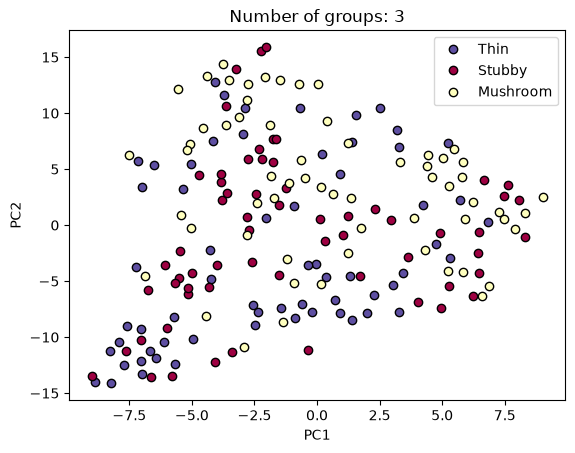

In [10]:
from spine_metrics import SpineMetricDataset
from spine_fitter import SpineGrouping
from volumetrics import get_equal_grouping
import matplotlib.pyplot as plt

# manual_classification_merged.json combines the annotators’ labels by majority vote.
# manual_classification_merged_reduced.json removes spines without a clear consensus and excludes Filopodia and Outlier.
# manual_classification_merged_reduced_strong_concensus.json is another filtered consensus set, with a stricter agreement requirement.

merged_grouping = SpineGrouping().load(f"{dataset_path}/manual_classification/manual_classification_merged_reduced.json")

merged_grouping = get_equal_grouping(merged_grouping)

metrics = SpineMetricDataset().load(f"{dataset_path}/metrics.csv")

## Get metrics for subset of spines
metrics = metrics.get_spines_subset(merged_grouping.samples)

## Determine classic metrics and chord distribution as seperate feature spaces
classic = metrics.get_metrics_subset(["OpenAngle", "CVD", "AverageDistance",
                                      "LengthVolumeRatio", "LengthAreaRatio", "JunctionArea",
                                      "Length", "Area", "Volume", "ConvexHullVolume", "ConvexHullRatio"])
chords = metrics.get_metrics_subset(["ChordDistribution"])

print("Merged expert classification")
merged_grouping.set_show_method(show_method)
merged_grouping._show(metrics)
plt.show()

## SVM Classification

3. Perform SVM classifiation on already classificated data to choose the classifier (classic/chord/combined) with the best accuracy.

In [ ]:
from sklearn import svm
from sklearn.model_selection import GridSearchCV
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import rbf_kernel, laplacian_kernel
from sklearn.metrics import pairwise_distances
from sklearn.linear_model import LinearRegression
from ipywidgets import widgets    
import csv
import random
import warnings
from notebook_widgets import create_dir
from histogram import histogram_intersection, histogram_intersection_pairwise, combined_kernel
from volumetrics import evaluate_classifier

warnings.filterwarnings(action='ignore', category=FutureWarning)
    

print(len(merged_grouping.samples))
for (key, value) in merged_grouping.groups.items():
    print(f"{key}: {len(value)}")

histogram_size = 100
random.seed(49)

scores = {}


ratios = np.linspace(0.1, 0.9, 9)

res_groupings = {}

input_metrics = {"Classic": (classic, 'rbf'), "Combined": (metrics, laplacian_kernel), "Chord": (chords, laplacian_kernel)}

## For each classifier determine the performance across different training ratios
for label, metric_set in input_metrics.items():
    res_groupings[label], _ = evaluate_classifier(label, metric_set[0], ratios, merged_grouping, scores, metric_set[1])

plt.xlabel("train / (train + test)")
plt.ylabel("mean accuracy")
plt.legend()

plt.show()


def export_graphs(_):
    save_folder = f"output/{dataset_path}/svm_classification"
    create_dir("output")
    create_dir(f"output/{dataset_path}")
    create_dir(save_folder)

    # save train graph
    filename = f"{save_folder}/training_accuracy_graphs.csv"
    with open(filename, mode="w") as file:
        writer = csv.writer(file)
        writer.writerow(["train_ratio"] + list(ratios))
        for label, score in scores.items():
            writer.writerow([label] + score)
    print(f"Saved training accuracy graphs to '{filename}'.")

    # save groupings
    for label, svm_grouping in res_groupings.items():
        save_path = f"{save_folder}/{label}"
        create_dir(save_path)
        svm_grouping.set_show_method(show_method)
        merged_grouping.set_show_method(show_method)
        svm_grouping.save(f"{save_path}/svm_classification.json")
        svm_grouping.save_reduced(input_metrics[label][0], f"{save_path}/svm_classification_{show_method}.csv", method=show_method)
        merged_grouping.save_reduced(input_metrics[label][0], f"{save_path}/manual_classification_{show_method}.csv", method=show_method)
        svm_grouping.save_metric_distribution(metrics, f"{save_path}/svm_classification_metric_distribution.csv")
        merged_grouping.save_metric_distribution(metrics, f"{save_path}/manual_classification_metric_distribution.csv")

        
export_button = widgets.Button(description="Export to .csv")
export_button.on_click(export_graphs)
display(export_button)

for label, res_grouping in res_groupings.items():
    metric_set = input_metrics[label][0]
    res_grouping.set_show_method(show_method)
    merged_grouping.set_show_method(show_method)
    display(widgets.HBox([widgets.VBox([widgets.Label("Manual classification:"), merged_grouping.show(metric_set)]),
                          widgets.VBox([widgets.Label(f"{label} metrics SVM classification:"), res_grouping.show(metric_set)])]))

## 2 Datasets

4. Perfrom classifiation for unlabeled test dataset using labeled train dataset. 

In [ ]:
from sklearn import svm
from sklearn.model_selection import GridSearchCV
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import pairwise_distances
from sklearn.linear_model import LinearRegression
from typing import Tuple    
from spine_metrics import SpineMetricDataset
from spine_fitter import SpineGrouping
from ipywidgets import widgets

    
# [Merged Grouping, Combined Metrics, Classic metrics, Chord metrics]
def load_dataset(dataset_path, labels_subpath: str = "") -> Tuple[SpineGrouping, SpineMetricDataset, SpineMetricDataset, SpineMetricDataset]:
    metrics = SpineMetricDataset().load(f"{dataset_path}/metrics.csv")

    if labels_subpath:
        grouping = SpineGrouping().load(f"{dataset_path}/{labels_subpath}")
        metrics = metrics.get_spines_subset(grouping.samples)
    
    else:
        grouping = SpineGrouping(groups={"Unlabeled": metrics.ordered_spine_names})

    classic = metrics.get_metrics_subset(["OpenAngle", "CVD", "AverageDistance",
                                          "LengthVolumeRatio", "LengthAreaRatio", "JunctionArea",
                                          "Length", "Area", "Volume", "ConvexHullVolume", "ConvexHullRatio"])
    chords = metrics.get_metrics_subset(["ChordDistribution"])

    return grouping, metrics, classic, chords


train = load_dataset("train example dataset", "manual_classification/manual_classification_merged_reduced.json")
test = load_dataset("test example dataset")


histogram_size = 100

def do_classification(label, train_grouping, train_metrics, test_grouping, test_metrics):
    pred_groupings = []

    train_names = train_metrics.ordered_spine_names
    test_names = test_metrics.ordered_spine_names

    train_target = [train_grouping.get_group(name) for name in train_names]
    test_target = [test_grouping.get_group(name) for name in test_names]

    parameters = {'C': [1, 10]}

    train_data = train_metrics.as_array()
    test_data = test_metrics.as_array()

    svc = svm.SVC(kernel="rbf")
    clf = GridSearchCV(svc, parameters, cv=4)
    clf.fit(train_data, train_target)
    print(f"{label} metrics SVM train accuracy = {clf.score(train_data, train_target)}")
    if not (len(test_grouping.groups) == 1 and "Unlabeled" in test_grouping.groups):
        print(f"{label} metrics SVM test accuracy = {clf.score(test_data, test_target)}")

    pred_labels = clf.predict(test_metrics.as_array())
    pred_groups = {label: set() for label in ["Thin", "Mushroom", "Stubby"]}
    for i, name in enumerate(test_metrics.ordered_spine_names):
        pred_groups[pred_labels[i]].add(name)
    pred_grouping = SpineGrouping(test_metrics.spine_names, pred_groups)
    test_grouping.set_show_method(show_method)
    pred_grouping.set_show_method(show_method)
    display(widgets.HBox([test_grouping.show(test_metrics), pred_grouping.show(test_metrics)]))
    return pred_grouping
    
    
res_groupings = {}
test_metrics = {"Classic": test[2], "Combined": test[1], "Chord": test[3]}


def export_graphs(_):
    save_folder = f"output/train_and_test_separately"
    create_dir("output")
    create_dir(save_folder)

    # save groupings
    for label, svm_grouping in res_groupings.items():
        save_path = f"{save_folder}/{label}"
        create_dir(save_path)
        svm_grouping.set_show_method(show_method)
        test[0].set_show_method(show_method)
        svm_grouping.save(f"{save_path}/svm_classification.json")
        svm_grouping.save_reduced(test_metrics[label], f"{save_path}/svm_classification_tsne.csv", method="tsne")
        test[0].save_reduced(test_metrics[label], f"{save_path}/manual_classification_tsne.csv", method="tsne")
        svm_grouping.save_metric_distribution(test_metrics["Combined"], f"{save_path}/svm_classification_metric_distribution.csv")
        test[0].save_metric_distribution(test_metrics["Combined"], f"{save_path}/manual_classification_metric_distribution.csv")
    print(f'Saved to "{save_folder}"')

        
export_button = widgets.Button(description="Export to .csv")
export_button.on_click(export_graphs)
display(export_button)

res_groupings["Classic"] = do_classification("Classic", train[0], train[2], test[0], test[2])
res_groupings["Combined"] = do_classification("Combined", train[0], train[1], test[0], test[1])
res_groupings["Chord"] = do_classification("Chord", train[0], train[3], test[0], test[3])

## Expert Accuracy

5. Calculate expert accuracy in manual classification.

In [ ]:
from pathlib import Path

path = Path(f"{dataset_path}/manual_classification")
classifications_paths = path.glob("manual_classification_?.json")
groupings = [SpineGrouping().load(str(path)) for path in classifications_paths]


for i, grouping in enumerate(groupings):
    print(f"{i + 1}: {SpineGrouping.accuracy(merged_grouping, grouping):.2f}")
print(f"Mean: {np.mean([SpineGrouping.accuracy(merged_grouping, grouping) for grouping in groupings]):.2f}")